# Breadcrumbs: whom should Kalpa call before October's due date?

This notebook walks your group up the ladder from Rohan's ask to a list Kalpa's team can call, one
stage per section. It asks the questions in order and leaves every decision to your group.

**Who needs the answer.** Rohan Desai, head of risk at Kalpa Financial. Before October's due date
his team calls the customers most likely to default. A missed default costs about five times a
wasted call, so a poor list costs him either missed defaults or days of wasted calls.

**The questions on the way.**

1. The frame: what is decided, from what is known when, about what outcome?
2. Requirements: what must the system do, how well, and within which rules?
3. Options: which two ways could make the decision, and which one do you choose?
4. The POC: does your list beat calling nobody on the error bill?
5. The architecture: which boxes sit inside the system, and what happens inside one of them?
6. The MVP slice: what could Rohan's team use tomorrow?

**How the notebook works.**

- The first cells have already run. They download the book and show what it holds.
- Every `__TODO__` is a decision for your group. A cell that still holds one stops with an error
  that names it, and that is expected.
- Every section ends on three sealed hints: a question, a pointer to a page, and the same step
  worked on a different problem.
- Stages 0 and 7, the business and the defence, live in your workbook and have no code.

## How does this notebook reach the code in `src/`?

The next cell finds the repository's top folder, the one that holds `src/`, and puts it on Python's
path, so `from src import data` works. It also loads `kit.py`, which sits beside this notebook and
draws the pictures and prints the checks.

In [1]:
import pathlib
import sys

import pandas as pd

# Find the repository's top folder, the one holding src/, wherever the notebook was opened from.
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]

import kit
from src import data, features, score, train

pd.set_option("display.max_columns", 30)  # so a printed table shows all 25 columns
print("Ready: src/ and kit.py are loaded.")

Ready: src/ and kit.py are loaded.


## Which stages does this notebook hold?

Your workbook gives every stage a page. This notebook holds the six stages that need code, lit in
the picture below, in the order your group climbs them from Tuesday to Friday.

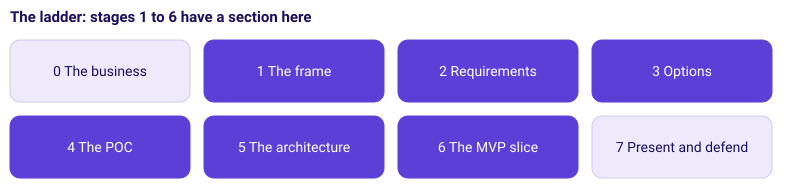

In [2]:
STAGES = ["0 The business", "1 The frame", "2 Requirements", "3 Options",
          "4 The POC", "5 The architecture", "6 The MVP slice", "7 Present and defend"]
kit.ladder(STAGES, lit=range(1, 7), title="The ladder: stages 1 to 6 have a section here")

## What did Rohan license, and what does the file hold?

Rohan licensed UCI's Default of Credit Card Clients, which the ticket describes: cardholders in
Taiwan, six monthly statements from April to September 2005, and whether each one defaulted in
October 2005. The next cell downloads it once into `data/` and reuses it after that, and
`.gitignore` keeps it out of your repository. Then the sheet is read the way pandas reads any
sheet, before your group has made a single choice.

In [3]:
sheet = data.download()
raw = data.read_raw(sheet)
print("File:", sheet.name, f"({sheet.stat().st_size / 1e6:.1f} MB)")
print("Shape (rows, columns):", raw.shape)

File: default of credit card clients.xls (5.5 MB)
Shape (rows, columns): (30001, 25)


In [4]:
raw.head(3)

,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1


In [5]:
kit.check("the sheet is on disk in data/", sheet.exists())
kit.check("the sheet has 25 columns", raw.shape[1] == 25)

PASS  the sheet is on disk in data/
PASS  the sheet has 25 columns


## What should your group check before trusting the book?

The sheet above is the raw material for `load_cards()` in `src/data.py`, which your group writes.
Before you write it, run four habits from earlier weeks, each in a cell of your own below this one.
Write every finding in `templates/CHALLENGES.md` as a question for Rohan or as a decision with its
reason.

1. **Reconcile.** Does every count you make agree with what the ticket says Rohan licensed? Start
   with the shape printed above.
2. **Read the names.** Could you explain every column name, and every printed row, to Rohan?
3. **Compare with the dictionary.** For each column, list the values it holds and compare them
   with the column table on the UCI page,
   https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients (checked 29 October 2026).
4. **Sort and read both ends.** Sort by each amount and read the smallest and the largest rows.

Once `load_cards()` is written, run `python -m pytest -rs` in the terminal. The first test checks
the row count.

In [ ]:
# __TODO__ Your audit: one habit per cell. Add a cell below this one for each habit.

## SECTION 1: The frame: what is decided, when?

*Before any model, write down the decision, the day it is made, what is known on that day and the
outcome it bets on.*

**Who needs the answer.** Rohan's team, who act on the list. A frame that leans on a column nobody
holds on the day the list is built gives Rohan a list he cannot build.

**The questions on the way.** What does Kalpa's team do to one customer? Who acts on the list? On
which day is the list built? Which columns exist on that day? What outcome does the list bet on,
and in which month is it known? What share of the book has that outcome?

Your group writes the frame on workbook page 2, on paper and with no AI. Once your TA has seen it,
copy it into the cell below, so the repository carries it.

In [ ]:
frame = {
    "decision": __TODO__,      # what Kalpa's team does to one customer, in one short sentence
    "acted_on_by": __TODO__,   # the role who acts on the list
    "moment": __TODO__,        # the day the list is built
    "known_then": __TODO__,    # the columns that exist on that day
    "outcome": __TODO__,       # what the list bets on, and the month it becomes known
}
kit.flow([frame["known_then"], frame["moment"], frame["decision"], frame["outcome"]],
         title="Your frame, in the order things happen")

### What share of the book has the outcome?

This share is the base rate, the first number in your passport. Every later number is read
against it.

In [ ]:
cards = data.load_cards()   # runs once your group has written load_cards in src/data.py
base_rate = __TODO__        # the share of the book whose outcome column is 1
print(f"Base rate: {base_rate:.3f}")
kit.check("every part of the frame is written", all(isinstance(v, str) and v.strip() for v in frame.values()))
kit.check("the base rate is a share between 0 and 1", 0 < base_rate < 1)

### Stuck on the frame after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

Which columns could a Kalpa caller see on the day the list is built, and which arrive later?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

Week 5 Monday: chapter 2, the notebook on input, target and prediction time, and case 1, "Whom should the bank call?". The week's explorer, page `#p1`.

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

Week 5's bank, framed. Your book has its own decision, day and outcome; this table shows only
the shape of a finished frame.

| Part of the frame | The bank in Week 5 |
|---|---|
| Decision | Call a client about a term deposit, or skip them |
| Acted on by | The bank's marketing team |
| Moment | The morning of the call |
| Known then | 13 columns about the client and earlier campaigns; the call's length is written when the call ends, so it stays out |
| Outcome | The client says yes, known after the call |
| Base rate | 4,640 of 41,188 clients said yes, 0.113 |

</details>

## SECTION 2: Requirements: what must it do?

*What must the system do, how well must it do it, within which limits, and under which security,
privacy and governance rules?*

**Who needs the answer.** Rohan and Kalpa's compliance team. A list that breaks a rule cannot be
used at all, however good its numbers look.

**The questions on the way.** What must the system do (the functional requirements)? How fast, how
often and how reliably must it do it (the non-functional requirements)? Which limits does your card
set (the constraints)? Who may see which data, and who answers for the list (security, privacy and
governance)?

Copy these from workbook page 3. Write each line so that a tester could answer it with yes or no.

In [ ]:
functional = [__TODO__]       # what the system must do
non_functional = [__TODO__]   # how well: how fast, how often, the same data giving the same list
constraints = [__TODO__]      # the limits, your card's rule first, in Rohan's words
governance = [__TODO__]       # security, privacy, who may see what, who signs off

for name, lines in [("Functional", functional), ("Non-functional", non_functional),
                    ("Constraints", constraints), ("Governance", governance)]:
    print(name)
    for line in lines:
        print("  -", line)

In [ ]:
kit.check("at least two functional and two non-functional requirements",
          len(functional) >= 2 and len(non_functional) >= 2)
kit.check("your card's rule is written as a constraint", len(constraints) >= 1)

### Stuck on the requirements after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

What would Kalpa's compliance team ask about a customer who gets a call they did not expect?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

The week's explorer, page `#p2`, the table of functional requirements, non-functional requirements and constraints. Eugene Yan's guide to design documents for ML systems, the part on requirements: https://eugeneyan.com/writing/ml-design-docs/ (checked 29 October 2026).

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

Requirements for Week 5's bank call list. These lines were written for this hint to show the
form; the bank published no rules with its data.

| Kind | An example line |
|---|---|
| Functional | Each morning, give the campaign team a list of clients, highest chance of a yes first |
| Non-functional | The list is ready before the first call, and the same data always gives the same list |
| Constraint | Only columns the bank holds on the morning of the call |
| Governance | Client data stays inside the bank, and the list goes only to the campaign team |

</details>

## SECTION 3: Options: which way, and why?

*Lay two ways to make the decision side by side, price each one, choose, and name the fact that
would flip your choice.*

**Who needs the answer.** Rohan, who pays for whatever the team builds. A model that a simple rule
could match costs weeks of work for nothing.

**The questions on the way.** What could Kalpa do with no model at all? What would a model add?
What does each cost to build, and can each say why a customer is on the list? Which one do you
choose? Which fact, if it changed, would flip your choice?

Copy option A and option B from workbook page 4. Section 4 then prices both on the same customers.

In [ ]:
option_a = {"name": __TODO__, "how_it_decides": __TODO__, "time_to_build": __TODO__, "can_say_why": __TODO__}
option_b = {"name": __TODO__, "how_it_decides": __TODO__, "time_to_build": __TODO__, "can_say_why": __TODO__}
chosen = __TODO__      # "A" or "B"
flip_fact = __TODO__   # the one fact that would make your group choose the other option

kit.check("one option is chosen", chosen in ("A", "B"))
kit.check("the fact that would flip the choice is written", isinstance(flip_fact, str) and bool(flip_fact.strip()))

### Stuck on the options after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

Could a simple rule, one a caller could apply with a pencil, do half the job?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

Google's Rules of Machine Learning, rule 1, "Don't be afraid to launch a product without machine learning": https://developers.google.com/machine-learning/guides/rules-of-ml (checked 29 October 2026). The week's explorer, page `#p3`.

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

Week 5 Tuesday's A against B for the bank, on 8,238 clients, when a wasted call cost Rs 40
and a missed buyer Rs 1,200.

| | Option A: call everyone | Option B: the model and a threshold |
|---|---|---|
| How it decides | No model: every client gets a call | Call when the chance of a yes is above 40 / (40 + 1,200) = 0.032 |
| Bill of mistakes | Rs 292,400 | Rs 279,000 |
| Can it say why? | There is nothing to explain | Each coefficient reads as a direction |

The bank chose B, by Rs 13,400, under 5 percent of the bill. The fact that flips it is a budget:
with only 1,000 calls, calling everyone is impossible, and the model's top 1,000 held 404 buyers
against about 112 for a random 1,000.

</details>

## SECTION 4: The POC: does it beat nothing?

*Score your two options on the 9,000 test customers and price each list against the two lists that
need no model.*

**Who needs the answer.** Rohan, who asks for the error bill of the list he hands over. A POC that
beats only a weak comparison gets money spent on a saving a rule already gets.

**The questions on the way.** What does calling nobody cost? What does calling everyone cost? Whom
does each of your options call, and what does each list cost? How far does your bill move on a
different split? Which numbers go in the passport?

The first cell runs your group's `src/` code from end to end and saves the model, which the demo
and the tests load. It runs once `load_cards`, `make_features` and `fit` are written.

In [ ]:
cards = data.load_cards()
learn, test = train.split_book(cards)   # 21,000 customers to learn from, 9,000 to test on
model = train.fit(features.make_features(learn), learn[data.TARGET])
score.save_model(model)                 # the demo and the tests load this file
X_test, outcome = features.make_features(test), test[data.TARGET]
print("Learned from", len(learn), "customers; testing on", len(test))

### Whom does each list call, and what does each one cost?

A list is one number per test customer: 1 if the list calls them, 0 if it skips them. Build one
list for option A and one for option B, with your card's rule applied to both. If your card
measures something else as well, such as balance protected, add a cell that computes it beside
the bill.

In [ ]:
called_a = __TODO__   # option A's list for the 9,000 test customers
called_b = __TODO__   # option B's list for the same customers

bill_nobody = train.error_bill(outcome, [0] * len(outcome))     # the do-nothing bill, passport number 2
bill_everyone = train.error_bill(outcome, [1] * len(outcome))
bill_a = train.error_bill(outcome, called_a)
bill_b = train.error_bill(outcome, called_b)
kit.bars([("Call nobody", bill_nobody), ("Call everyone", bill_everyone),
          ("Option A", bill_a), ("Option B", bill_b)],
         title="The error bill on the 9,000 test customers")

In [ ]:
bill_chosen = bill_a if chosen == "A" else bill_b   # passport number 4
kit.check("calling nobody costs every defaulter at the miss cost",
          bill_nobody == outcome.sum() * train.MISS_COST)
kit.check("the chosen list costs less than calling nobody", bill_chosen < bill_nobody)

### How far does the bill move on a different split?

One split is one draw. Slide 5 asks how honest your number is, and the spread across five splits
is part of the answer.

In [ ]:
bills = []
for seed in range(5):
    learn_s, test_s = train.split_book(cards, seed=seed)
    bills.append(__TODO__)   # fit on learn_s, build your chosen list on test_s, and price it
print(f"Chosen list on five splits: lowest bill {min(bills):,.0f}, highest {max(bills):,.0f}")
kit.check("five bills were measured", len(bills) == 5)

### Stuck on the POC after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

What does calling nobody cost, and what does calling everyone cost? Your list has to beat the cheaper of the two, so which one is it for your card?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

Week 5 Tuesday: case 2, "The cost threshold", and case 3, "The budget". The week's explorer, page `#p4`.

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

Five bank clients, invented for this hint, priced the way Week 5 priced them: a wasted call
costs Rs 40 and a missed buyer Rs 1,200.

| Client | Bought? | Called? | The mistake | Cost |
|---|---|---|---|---|
| 1 | yes | yes | none | 0 |
| 2 | no | yes | a wasted call | Rs 40 |
| 3 | no | no | none | 0 |
| 4 | yes | no | a missed buyer | Rs 1,200 |
| 5 | no | no | none | 0 |

The bill is Rs 1,240. On Week 5's real 8,238 clients, calling everyone whose chance of a yes was
above 40 / 1,240 = 0.032 called 7,438 clients, found 913 of the 928 buyers, and left a bill of
Rs 279,000 against Rs 292,400 for calling everyone.

</details>

## SECTION 5: The architecture: what sits inside?

*Draw the system as one black box, open it into its high-level boxes, then zoom into one box and
write its low-level design.*

**Who needs the answer.** Kalpa's engineers, who would run this every month, and Saturday's panel.
A design that skips a box hides the place where the list can break.

**The questions on the way.** What goes into the black box, what comes out, and who uses it? Which
boxes sit inside it, in order? For one box, what are its inputs, its steps and its outputs? What
happens to the design when your card's twist lands on Thursday?

Copy the design from workbook page 6, then let the cells draw it.

In [ ]:
black_box = {"goes_in": __TODO__, "comes_out": __TODO__, "used_by": __TODO__}
boxes = [__TODO__]   # the high-level design, in order, from the data arriving to the call being made
kit.flow(boxes, title="Our high-level design")

In [ ]:
zoom = {"box": __TODO__, "inputs": __TODO__, "steps": [__TODO__], "outputs": __TODO__}
kit.flow(zoom["steps"], title="Inside one box: the low-level design")
kit.check("the high-level design has at least four boxes", len(boxes) >= 4)
kit.check("the zoomed box is one of them", zoom["box"] in boxes)

### Stuck on the architecture after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

What breaks if the data arrives a day late?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

The week's explorer, page `#p5`. Made With ML's lesson on systems design: https://madewithml.com/courses/mlops/systems-design/ (checked 29 October 2026). The four files in `src/` are four of your boxes already.

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

A design for Week 5's bank call list, written for this hint to show the form.

High-level design, in order: the client table, then the feature step, then the model, then the
ranked list, then the campaign team's calls. The call outcomes flow back into the client table,
and the model is fitted again each month.

| Low-level design of the feature step | |
|---|---|
| Inputs | One row of the client table |
| Step 1 | Keep only the columns the bank holds on the morning of the call |
| Step 2 | Turn `pdays` 999 into two columns, never contacted and days since contact (Week 5 Wednesday) |
| Outputs | One row of numbers per client, in the same column order every time |

</details>

## SECTION 6: The MVP slice: what ships tomorrow?

*Score one customer the way a caller would see them, then write what the POC proved and what an MVP
and production still need.*

**Who needs the answer.** A Kalpa caller, who needs one customer's chance and reason before
dialling, and Rohan, who decides whether to fund the next step. An MVP that cannot say why a
customer is on the list cannot be used on a call.

**The questions on the way.** Does `score()` give one customer's chance and a reason a caller can
say? Does one customer get the same input columns as 9,000 customers? What does the demo show when
your card's number changes? What did the POC prove, and what must the MVP and production add?

In [ ]:
customer = test.iloc[0]
probability, reason = score.score(customer)   # runs once your group has written score in src/score.py
print(f"Chance of default: {probability:.0%}. Main reason: {reason}")
kit.check("the probability is between 0 and 1", 0 <= probability <= 1)
kit.check("one customer gets the same input columns as the test book",
          list(features.make_features(test.iloc[[0]]).columns) == list(X_test.columns))

### What does the demo show a caller?

Start the demo from the terminal with `streamlit run app/app.py`, or with `python app/no_server.py`
if the page will not open. Then add the control your card changes where `app/app.py` says
`__TODO__`, and change your card's number live, as slide 3 will.

In [ ]:
mvp_plan = {
    "poc_proved": __TODO__,         # one sentence, with your bill against calling nobody in it
    "mvp_adds": [__TODO__],         # what a caller needs that the POC skipped
    "production_adds": [__TODO__],  # what running every month needs: checks over time, monitoring, an owner
}
kit.check("the plan names what the MVP adds and what production adds",
          len(mvp_plan["mvp_adds"]) >= 1 and len(mvp_plan["production_adds"]) >= 1)

### Stuck on the MVP slice after a real try?

Each hint below is sealed. Open one only at the daily checkpoint, with your TA beside you, and write
it in `templates/CHALLENGES.md`: which hint, and what your group did next.

<details>
<summary><b>Sealed hint 1, a question.</b></summary>

What does a Kalpa caller click, and what do they read before dialling?

</details>

<details>
<summary><b>Sealed hint 2, a pointer.</b></summary>

`app/app.py` in this repository. The week's explorer, page `#p6`. Google Cloud's three MLOps levels, from a manual process to automated pipelines: https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning (checked 29 October 2026).

</details>

<details>
<summary><b>Sealed hint 3, the same step on a different problem.</b></summary>

Week 5 Friday took the bank's model through time. Trained on the early months and used on
the late ones, its AUC fell from 0.80 to 0.66, and the real buying rate rose from about 6 to about
25 in 100 while the model still promised about 16. The bank's MVP was the call list with a reason
beside each client; production added the rule that would have caught the drift: compare the
promise with what really happened among called clients, and act when they part by ten points two
months running.

</details>

## Where does each passport number come from?

Every member carries these five numbers, says what each one means, and can point to the cell that
computes it.

| Passport number | Where this notebook computes it |
|---|---|
| 1. The base rate | Section 1, `base_rate` |
| 2. The do-nothing bill | Section 4, `bill_nobody` |
| 3. The chosen threshold or list size | Section 4, the cell that builds `called_a` and `called_b` |
| 4. The model's bill | Section 4, `bill_chosen` |
| 5. Your card's number | `src/train.py` for a cost, or the cell your card changes |

Two honesty lines travel with every number. The Taiwan score proves the pipeline and is never
Kalpa's score. This data allows no out-of-time split, so the MVP must add one.